In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import os

dataset_path = "../Dataset"

print(os.listdir(dataset_path))

['Sample - Superstore.csv']


In [3]:
df = pd.read_csv("../Dataset/Sample - Superstore.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

UnicodeDecodeError: 'utf-8' codec can't decode byte 0xf6 in position 9: invalid start byte

In [4]:
df = pd.read_csv(
    "../Dataset/Sample - Superstore.csv",
    encoding="latin1"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (9994, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Post

In [6]:
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values in Each Column:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Total Missing Values: 0


In [7]:
duplicates = df.duplicated().sum()

print("Total Duplicate Records:", duplicates)

Total Duplicate Records: 0


In [8]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

print("Date Columns Converted Successfully!")
print(df[["Order Date", "Ship Date"]].dtypes)

Date Columns Converted Successfully!
Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object


In [9]:
df.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2016-04-30 00:07:12.259355,2016-05-03 23:06:58.571142,55190.379428,229.858001,3.789574,0.156203,28.656896
min,1.000000,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000
std,2885.163629,NaN,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108


In [10]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"{col}: {df[col].nunique()} unique values")

Order ID: 5009 unique values
Ship Mode: 4 unique values
Customer ID: 793 unique values
Customer Name: 793 unique values
Segment: 3 unique values
Country: 1 unique values
City: 531 unique values
State: 49 unique values
Region: 4 unique values
Product ID: 1862 unique values
Category: 3 unique values
Sub-Category: 17 unique values
Product Name: 1850 unique values


C:\Users\Rupesh.Amin\AppData\Local\Temp\ipykernel_2108\1291878943.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns


In [11]:
categorical_columns = df.select_dtypes(include="str").columns

for col in categorical_columns:
    print(f"{col}: {df[col].nunique()} unique values")

Order ID: 5009 unique values
Ship Mode: 4 unique values
Customer ID: 793 unique values
Customer Name: 793 unique values
Segment: 3 unique values
Country: 1 unique values
City: 531 unique values
State: 49 unique values
Region: 4 unique values
Product ID: 1862 unique values
Category: 3 unique values
Sub-Category: 17 unique values
Product Name: 1850 unique values


In [12]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

print("Category-wise Sales:")
print(category_sales)

Category-wise Sales:
Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64


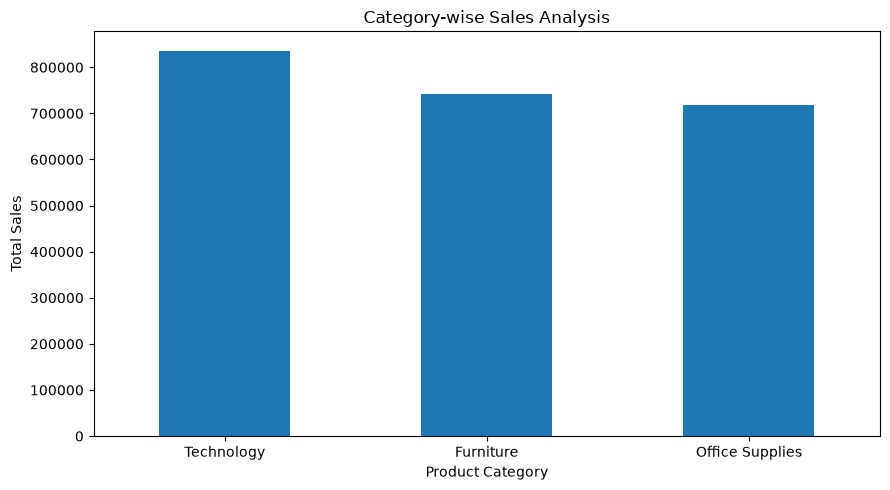

In [13]:
plt.figure(figsize=(9, 5))

category_sales.plot(kind="bar")

plt.title("Category-wise Sales Analysis")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../Visualizations/category_sales.png")
plt.show()

In [14]:
subcategory_sales = df.groupby("Sub-Category")["Sales"].sum().sort_values(ascending=False)

print("Sub-Category-wise Sales:")
print(subcategory_sales)

Sub-Category-wise Sales:
Sub-Category
Phones         330007.0540
Chairs         328449.1030
Storage        223843.6080
Tables         206965.5320
Binders        203412.7330
Machines       189238.6310
Accessories    167380.3180
Copiers        149528.0300
Bookcases      114879.9963
Appliances     107532.1610
Furnishings     91705.1640
Paper           78479.2060
Supplies        46673.5380
Art             27118.7920
Envelopes       16476.4020
Labels          12486.3120
Fasteners        3024.2800
Name: Sales, dtype: float64


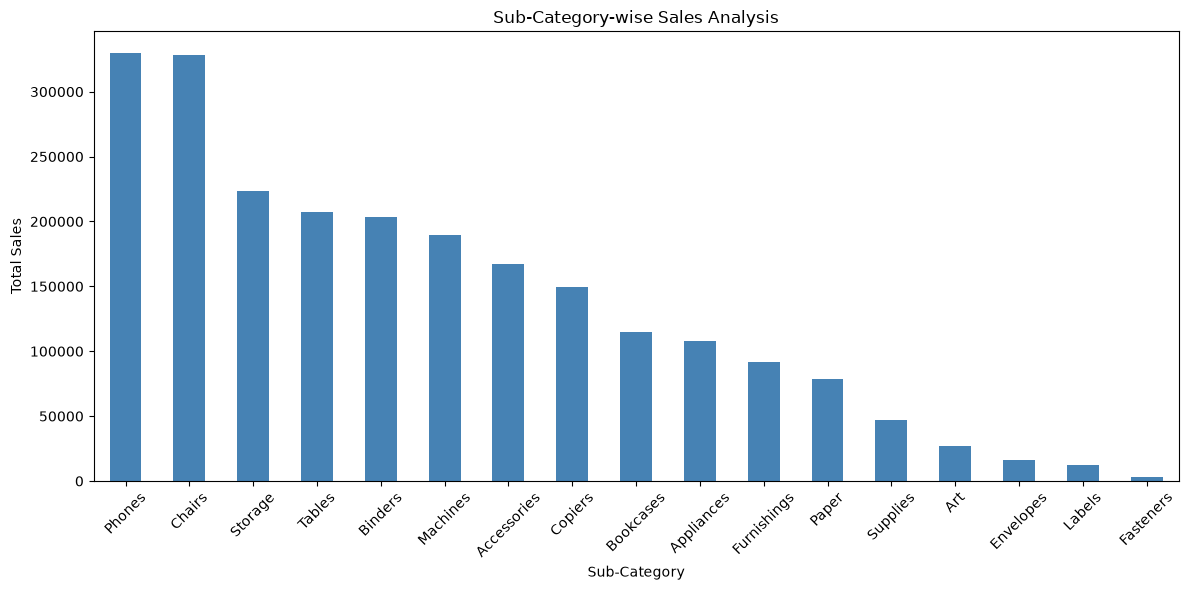

In [15]:
plt.figure(figsize=(12, 6))

subcategory_sales.plot(kind="bar", color="steelblue")

plt.title("Sub-Category-wise Sales Analysis")
plt.xlabel("Sub-Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("../Visualizations/subcategory_sales.png")
plt.show()

In [16]:
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

print("Region-wise Sales:")
print(region_sales)

Region-wise Sales:
Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64


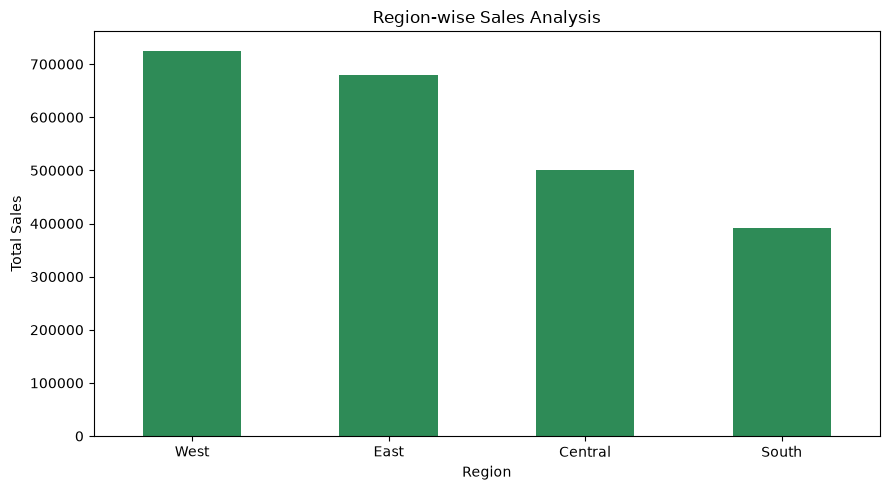

In [17]:
plt.figure(figsize=(9, 5))

region_sales.plot(kind="bar", color="seagreen")

plt.title("Region-wise Sales Analysis")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../Visualizations/region_sales.png")
plt.show()

In [18]:
category_profit = df.groupby("Category")["Profit"].sum().sort_values(ascending=False)

print("Category-wise Profit:")
print(category_profit)

Category-wise Profit:
Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64


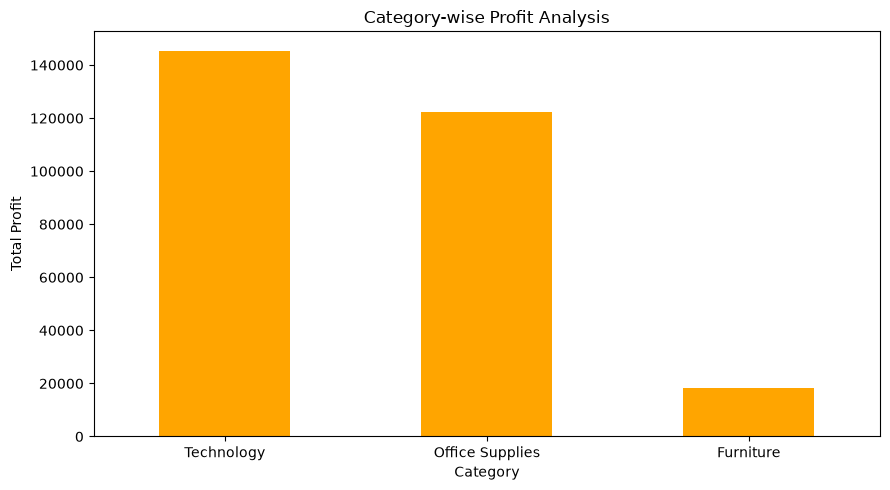

In [19]:
plt.figure(figsize=(9, 5))

category_profit.plot(kind="bar", color="orange")

plt.title("Category-wise Profit Analysis")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../Visualizations/category_profit.png")
plt.show()

In [20]:
region_profit = df.groupby("Region")["Profit"].sum().sort_values(ascending=False)

print("Region-wise Profit:")
print(region_profit)

Region-wise Profit:
Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64


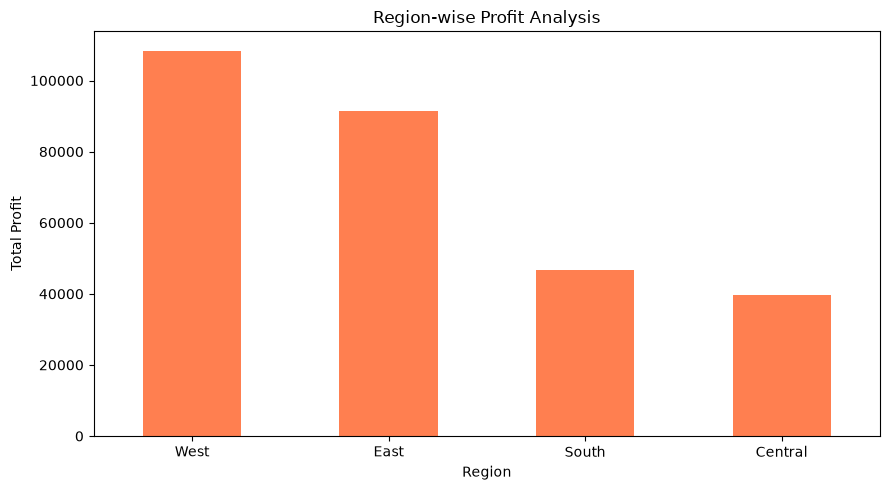

In [21]:
plt.figure(figsize=(9, 5))

region_profit.plot(kind="bar", color="coral")

plt.title("Region-wise Profit Analysis")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../Visualizations/region_profit.png")
plt.show()

In [22]:
segment_sales = df.groupby("Segment")["Sales"].sum().sort_values(ascending=False)

print("Segment-wise Sales:")
print(segment_sales)

Segment-wise Sales:
Segment
Consumer       1.161401e+06
Corporate      7.061464e+05
Home Office    4.296531e+05
Name: Sales, dtype: float64


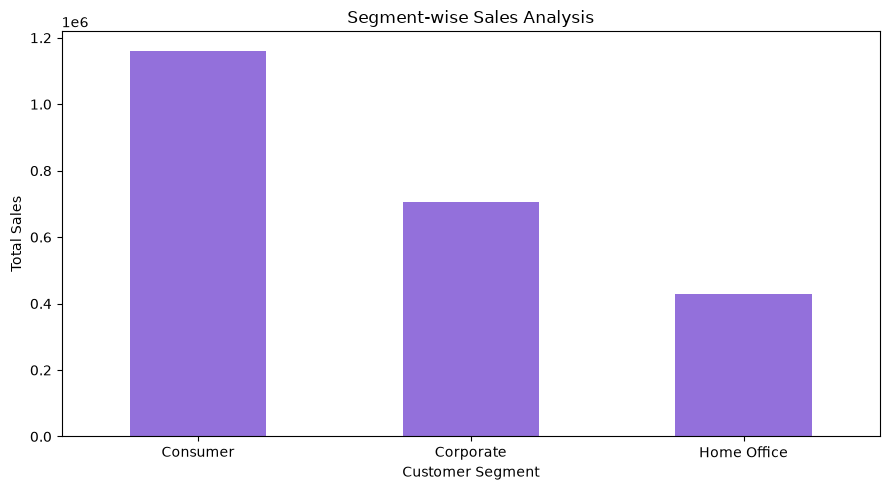

In [23]:
plt.figure(figsize=(9, 5))

segment_sales.plot(kind="bar", color="mediumpurple")

plt.title("Segment-wise Sales Analysis")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../Visualizations/segment_sales.png")
plt.show()

In [24]:
segment_profit = df.groupby("Segment")["Profit"].sum().sort_values(ascending=False)

print("Segment-wise Profit:")
print(segment_profit)

Segment-wise Profit:
Segment
Consumer       134119.2092
Corporate       91979.1340
Home Office     60298.6785
Name: Profit, dtype: float64


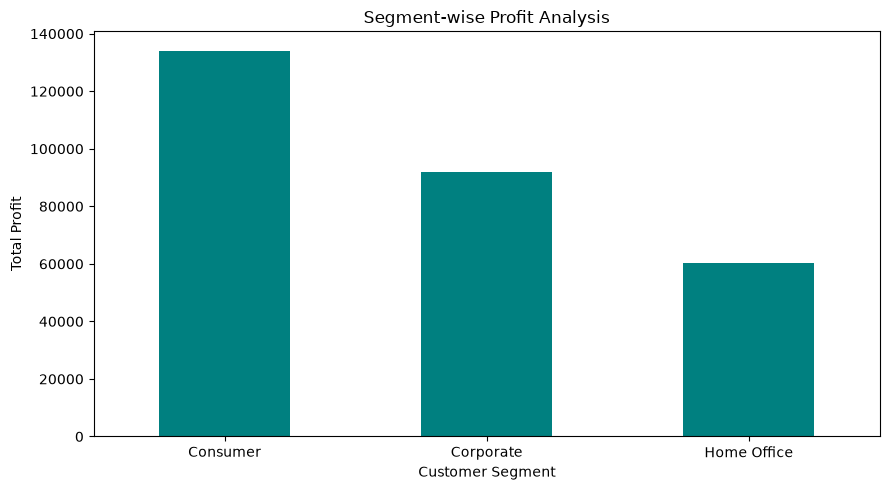

In [25]:
plt.figure(figsize=(9, 5))

segment_profit.plot(kind="bar", color="teal")

plt.title("Segment-wise Profit Analysis")
plt.xlabel("Customer Segment")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../Visualizations/segment_profit.png")
plt.show()

In [26]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month

monthly_sales = df.groupby("Month")["Sales"].sum()

print("Monthly Sales:")
print(monthly_sales)

Monthly Sales:
Month
1      94924.8356
2      59751.2514
3     205005.4888
4     137762.1286
5     155028.8117
6     152718.6793
7     147238.0970
8     159044.0630
9     307649.9457
10    200322.9847
11    352461.0710
12    325293.5035
Name: Sales, dtype: float64


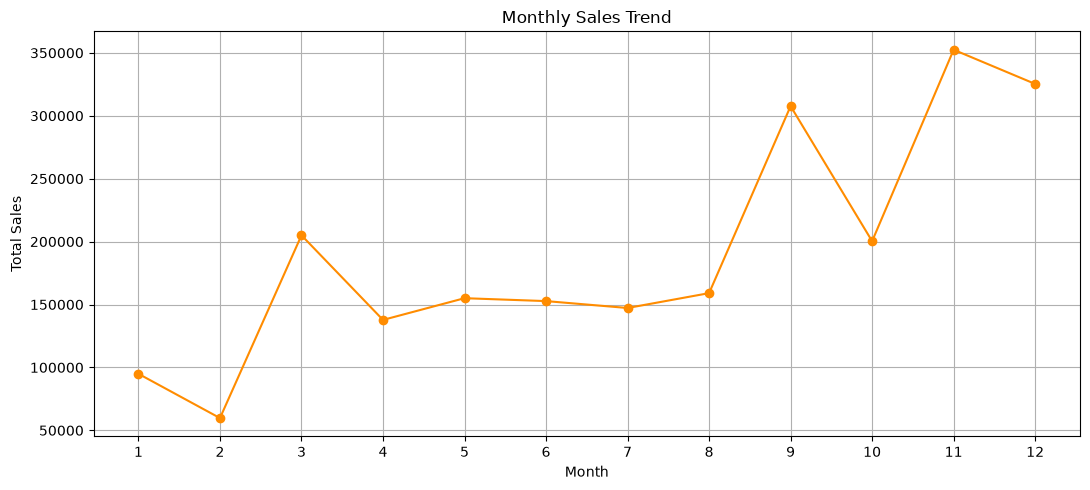

In [27]:
plt.figure(figsize=(11, 5))

monthly_sales.plot(kind="line", marker="o", color="darkorange")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()

plt.savefig("../Visualizations/monthly_sales.png")
plt.show()

In [28]:
yearly_sales = df.groupby("Year")["Sales"].sum().sort_index()

print("Year-wise Sales:")
print(yearly_sales)

Year-wise Sales:
Year
2014    484247.4981
2015    470532.5090
2016    609205.5980
2017    733215.2552
Name: Sales, dtype: float64


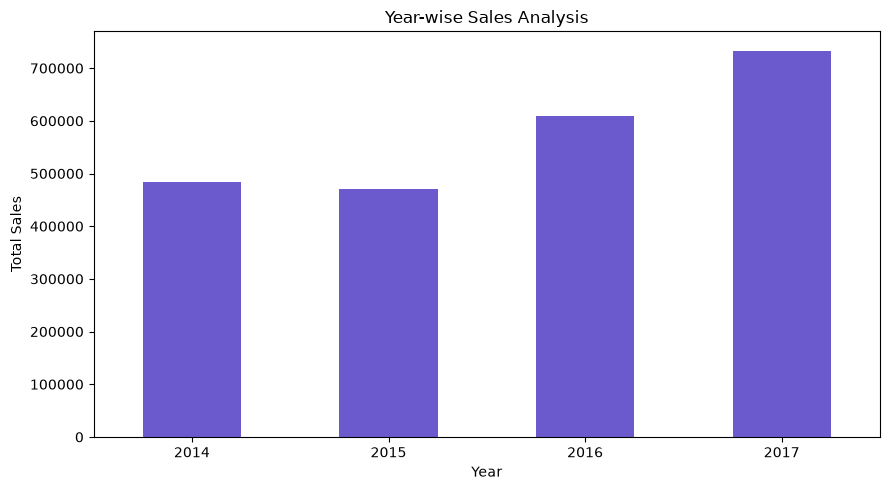

In [29]:
plt.figure(figsize=(9, 5))

yearly_sales.plot(kind="bar", color="slateblue")

plt.title("Year-wise Sales Analysis")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../Visualizations/yearly_sales.png")
plt.show()

In [30]:
yearly_profit = df.groupby("Year")["Profit"].sum().sort_index()

print("Year-wise Profit:")
print(yearly_profit)

Year-wise Profit:
Year
2014    49543.9741
2015    61618.6037
2016    81795.1743
2017    93439.2696
Name: Profit, dtype: float64


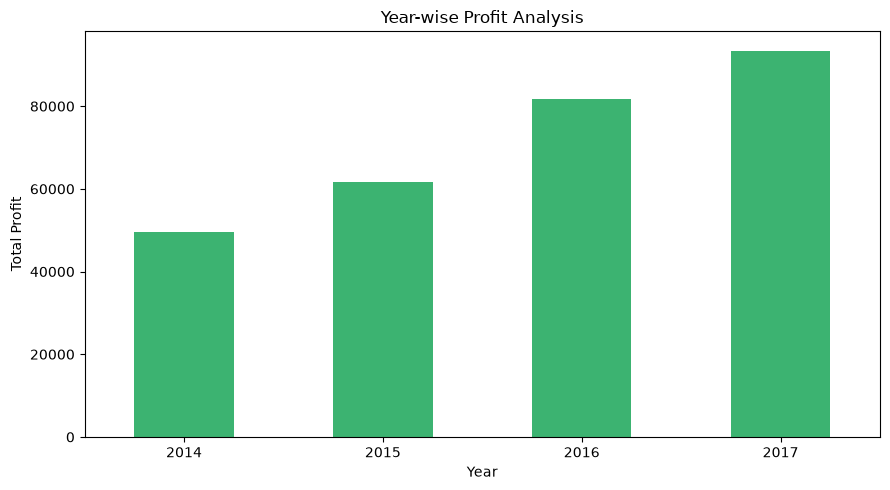

In [31]:
plt.figure(figsize=(9, 5))

yearly_profit.plot(kind="bar", color="mediumseagreen")

plt.title("Year-wise Profit Analysis")
plt.xlabel("Year")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../Visualizations/yearly_profit.png")
plt.show()

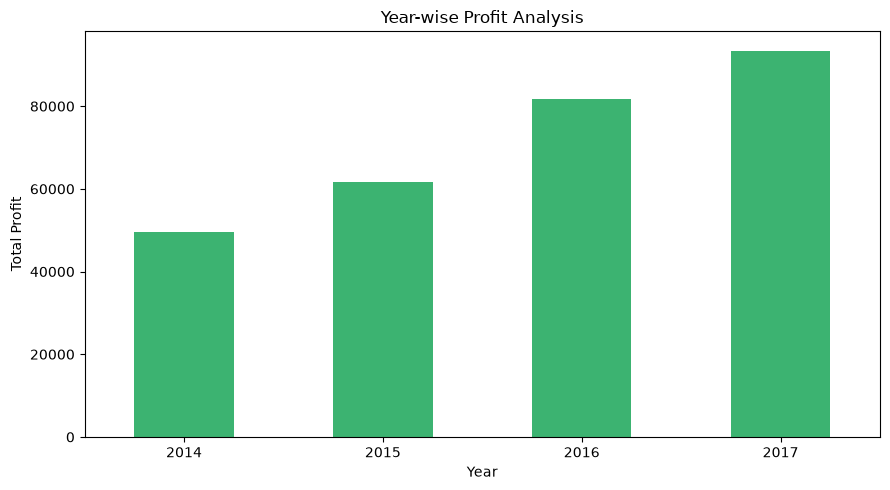

In [32]:
plt.figure(figsize=(9, 5))

yearly_profit.plot(kind="bar", color="mediumseagreen")

plt.title("Year-wise Profit Analysis")
plt.xlabel("Year")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../Visualizations/yearly_profit.png")
plt.show()

In [33]:
discount_profit = df.groupby("Discount")["Profit"].mean()

print("Discount-wise Average Profit:")
print(discount_profit)

Discount-wise Average Profit:
Discount
0.00     66.900292
0.10     96.055074
0.15     27.288298
0.20     24.702572
0.30    -45.679636
0.32    -88.560656
0.40   -111.927429
0.45   -226.646464
0.50   -310.703456
0.60    -43.077212
0.70    -95.874060
0.80   -101.796797
Name: Profit, dtype: float64


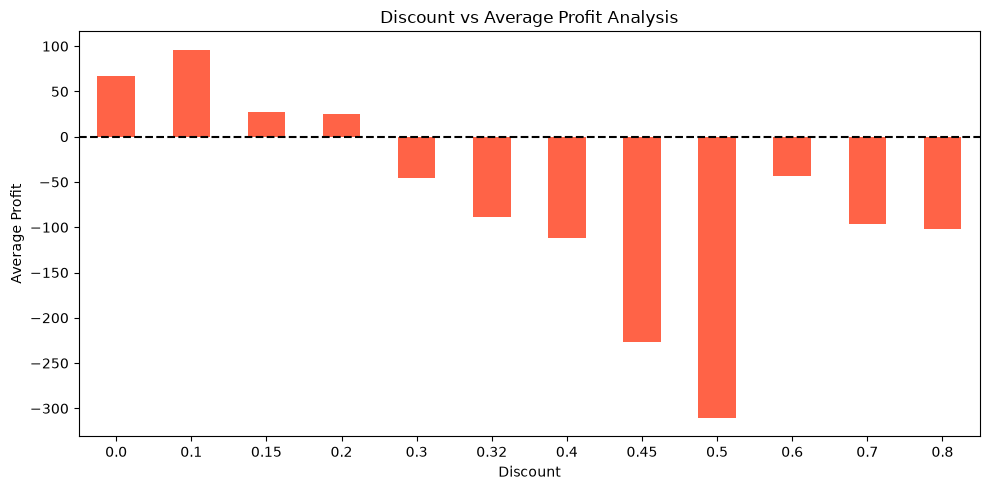

In [34]:
plt.figure(figsize=(10, 5))

discount_profit.plot(kind="bar", color="tomato")

plt.title("Discount vs Average Profit Analysis")
plt.xlabel("Discount")
plt.ylabel("Average Profit")
plt.axhline(y=0, color="black", linestyle="--")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../Visualizations/discount_profit.png")
plt.show()

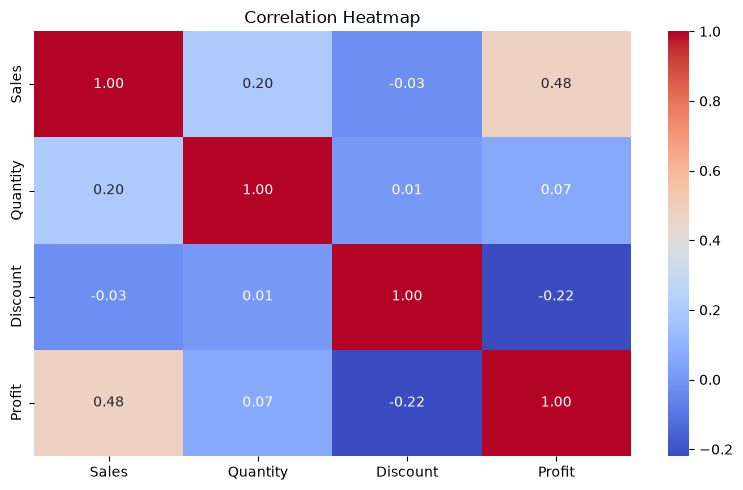

In [35]:
plt.figure(figsize=(8, 5))

correlation = df[["Sales", "Quantity", "Discount", "Profit"]].corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("../Visualizations/correlation_heatmap.png")
plt.show()

In [36]:
import os

print("Total Graphs:", len(os.listdir("../Visualizations")))
print("Saved Graphs:")

for file in os.listdir("../Visualizations"):
    print(file)

Total Graphs: 12
Saved Graphs:
category_profit.png
category_sales.png
correlation_heatmap.png
discount_profit.png
monthly_sales.png
region_profit.png
region_sales.png
segment_profit.png
segment_sales.png
subcategory_sales.png
yearly_profit.png
yearly_sales.png


In [37]:
print("========== EDA PROJECT SUMMARY ==========")

print("Total Records:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nDataset Date Range:")
print("Start Date:", df["Order Date"].min())
print("End Date:", df["Order Date"].max())

print("\nTotal Sales:", round(df["Sales"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))
print("Average Sales:", round(df["Sales"].mean(), 2))
print("Average Profit:", round(df["Profit"].mean(), 2))

print("\nTotal Customers:", df["Customer ID"].nunique())
print("Total Products:", df["Product ID"].nunique())
print("Total Categories:", df["Category"].nunique())

print("\n========== SUMMARY COMPLETE ==========")

========== EDA PROJECT SUMMARY ==========
Total Records: 9994
Total Columns: 23

Dataset Date Range:
Start Date: 2014-01-03 00:00:00
End Date: 2017-12-30 00:00:00

Total Sales: 2297200.86
Total Profit: 286397.02
Average Sales: 229.86
Average Profit: 28.66

Total Customers: 793
Total Products: 1862
Total Categories: 3

========== SUMMARY COMPLETE ==========


In [38]:
print("KEY BUSINESS FINDINGS")

print("\n1. Highest Sales Category:")
print(df.groupby("Category")["Sales"].sum().idxmax())

print("\n2. Highest Profit Category:")
print(df.groupby("Category")["Profit"].sum().idxmax())

print("\n3. Highest Sales Region:")
print(df.groupby("Region")["Sales"].sum().idxmax())

print("\n4. Highest Profit Region:")
print(df.groupby("Region")["Profit"].sum().idxmax())

print("\n5. Highest Sales Segment:")
print(df.groupby("Segment")["Sales"].sum().idxmax())

print("\n6. Highest Sales Year:")
print(df.groupby("Year")["Sales"].sum().idxmax())

print("\n7. Most Profitable Discount:")
print(df.groupby("Discount")["Profit"].mean().idxmax())

print("\n8. Lowest Average Profit Discount:")
print(df.groupby("Discount")["Profit"].mean().idxmin())

KEY BUSINESS FINDINGS

1. Highest Sales Category:
Technology

2. Highest Profit Category:
Technology

3. Highest Sales Region:
West

4. Highest Profit Region:
West

5. Highest Sales Segment:
Consumer

6. Highest Sales Year:
2017

7. Most Profitable Discount:
0.1

8. Lowest Average Profit Discount:
0.5


In [39]:
import reportlab

print("ReportLab is installed successfully!")

ReportLab is installed successfully!


In [40]:
import os
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import inch
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image,
    PageBreak, Table, TableStyle
)

# Project folders
base_path = os.path.abspath("..")
visual_path = os.path.join(base_path, "Visualizations")
report_path = os.path.join(base_path, "Report")

os.makedirs(report_path, exist_ok=True)

pdf_file = os.path.join(report_path, "ECommerce_EDA_Final_Report.pdf")

doc = SimpleDocTemplate(
    pdf_file,
    pagesize=A4,
    rightMargin=45,
    leftMargin=45,
    topMargin=45,
    bottomMargin=45
)

styles = getSampleStyleSheet()
story = []

title_style = ParagraphStyle(
    "MainTitle", parent=styles["Title"],
    fontSize=23, textColor=colors.darkblue,
    spaceAfter=18
)

heading_style = ParagraphStyle(
    "HeadingCustom", parent=styles["Heading2"],
    textColor=colors.darkblue, spaceBefore=12
)

# Cover Page
story.append(Spacer(1, 100))
story.append(Paragraph("E-COMMERCE SALES DATA ANALYSIS", title_style))
story.append(Paragraph("Exploratory Data Analysis (EDA) Project", styles["Heading2"]))
story.append(Spacer(1, 25))
story.append(Paragraph("Dataset: Sample Superstore", styles["Normal"]))
story.append(Paragraph("Analysis Period: 2014 – 2017", styles["Normal"]))
story.append(Paragraph("Tools: Python, Pandas, NumPy, Matplotlib, Seaborn", styles["Normal"]))
story.append(Spacer(1, 30))
story.append(Paragraph("Final Project Report", styles["Heading2"]))
story.append(PageBreak())

# Introduction
story.append(Paragraph("1. Introduction", heading_style))
story.append(Paragraph(
    "Exploratory Data Analysis (EDA) is the process of examining and "
    "understanding a dataset using statistical summaries and visualizations. "
    "This project analyzes an E-Commerce Sample Superstore dataset to "
    "identify sales trends, profitability patterns, and business insights.",
    styles["BodyText"]
))

# Objectives
story.append(Paragraph("2. Project Objectives", heading_style))
objectives = [
    "Understand the structure of the sales dataset.",
    "Check and handle missing values and duplicate records.",
    "Analyze sales and profit across categories and regions.",
    "Study monthly and yearly sales trends.",
    "Understand the relationship between discounts and profit.",
    "Generate visualizations and meaningful business insights."
]
for item in objectives:
    story.append(Paragraph("• " + item, styles["BodyText"]))

# Dataset Description
story.append(Paragraph("3. Dataset Description", heading_style))
dataset_data = [
    ["Metric", "Value"],
    ["Total Records", "9,994"],
    ["Original Columns", "21"],
    ["Columns After Feature Creation", "23"],
    ["Total Customers", "793"],
    ["Total Products", "1,862"],
    ["Categories", "3"],
    ["Total Sales", "2,297,200.86"],
    ["Total Profit", "286,397.02"],
    ["Analysis Period", "2014–2017"]
]
table = Table(dataset_data, colWidths=[220, 220])
table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.darkblue),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("PADDING", (0, 0), (-1, -1), 7)
]))
story.append(table)

# Data Cleaning
story.append(Paragraph("4. Data Cleaning and Preprocessing", heading_style))
cleaning_points = [
    "Loaded the Sample Superstore CSV dataset using Pandas.",
    "Converted Order Date and Ship Date into datetime format.",
    "Checked all columns for missing values; none were found.",
    "Checked duplicate records; zero duplicates were found.",
    "Created Year and Month columns from Order Date for time-based analysis.",
    "Dataset contained 9,994 records after preprocessing."
]
for item in cleaning_points:
    story.append(Paragraph("• " + item, styles["BodyText"]))

# Analysis and Visualizations
story.append(PageBreak())
story.append(Paragraph("5. Exploratory Data Analysis and Visualizations", heading_style))

graphs = [
    ("category_sales.png", "Category-wise Sales",
     "Technology recorded the highest sales among the three product categories."),
    ("subcategory_sales.png", "Sub-Category-wise Sales",
     "Phones recorded the highest sales, while Fasteners recorded the lowest."),
    ("region_sales.png", "Region-wise Sales",
     "The West region generated the highest sales, while the South generated the lowest."),
    ("category_profit.png", "Category-wise Profit",
     "Technology generated the highest profit. Furniture generated substantially lower profit."),
    ("region_profit.png", "Region-wise Profit",
     "The West region generated the highest profit, while Central recorded the lowest."),
    ("segment_sales.png", "Segment-wise Sales",
     "The Consumer segment generated the highest sales."),
    ("segment_profit.png", "Segment-wise Profit",
     "The Consumer segment generated the highest profit."),
    ("monthly_sales.png", "Monthly Sales Trend",
     "November recorded the highest monthly sales, while February recorded the lowest."),
    ("yearly_sales.png", "Year-wise Sales",
     "2017 recorded the highest annual sales during the analysis period."),
    ("yearly_profit.png", "Year-wise Profit",
     "Annual profit increased from 2014 through 2017."),
    ("discount_profit.png", "Discount vs Average Profit",
     "A 10% discount had the highest average profit. A 50% discount had the lowest average profit."),
    ("correlation_heatmap.png", "Correlation Heatmap",
     "The heatmap displays correlations among Sales, Quantity, Discount, and Profit.")
]

for filename, heading, description in graphs:
    image_path = os.path.join(visual_path, filename)

    story.append(Paragraph(heading, heading_style))
    story.append(Paragraph(description, styles["BodyText"]))
    story.append(Spacer(1, 8))

    if os.path.exists(image_path):
        img = Image(image_path)
        img._restrictSize(450, 260)
        story.append(img)
    else:
        story.append(Paragraph(
            "Visualization file not found: " + filename,
            styles["BodyText"]
        ))

    story.append(Spacer(1, 12))

# Key Findings
story.append(PageBreak())
story.append(Paragraph("6. Key Business Findings", heading_style))

findings = [
    "Technology is the highest sales and profit generating category.",
    "West is the leading region in both sales and profit.",
    "Consumer is the highest sales and profit generating segment.",
    "2017 recorded the highest annual sales.",
    "A 10% discount had the highest average profit.",
    "A 50% discount had the lowest average profit."
]
for finding in findings:
    story.append(Paragraph("• " + finding, styles["BodyText"]))

# Conclusion
story.append(Paragraph("7. Conclusion", heading_style))
story.append(Paragraph(
    "The EDA project provided useful insights into the Sample Superstore "
    "dataset. Technology and the West region performed strongly in terms "
    "of sales and profit. The Consumer segment contributed the highest "
    "sales and profit, and 2017 was the strongest year in the dataset. "
    "The discount analysis showed that higher discounts can be associated "
    "with lower average profit at several discount levels. Overall, this "
    "analysis demonstrates how Python-based data analysis and visualization "
    "can help identify business trends and support better decisions.",
    styles["BodyText"]
))

# Footer
def add_footer(canvas, doc):
    canvas.saveState()
    canvas.setFont("Helvetica", 8)
    canvas.drawString(45, 25, "E-Commerce Sales EDA Project")
    canvas.drawRightString(550, 25, f"Page {doc.page}")
    canvas.restoreState()

doc.build(story, onFirstPage=add_footer, onLaterPages=add_footer)

print("Final Report PDF Created Successfully!")
print("Location:", pdf_file)
print("PDF Exists:", os.path.exists(pdf_file))

Final Report PDF Created Successfully!
Location: C:\Users\Rupesh.Amin\Desktop\EDA_ECommerce_Project\Report\ECommerce_EDA_Final_Report.pdf
PDF Exists: True
